**Distribution of Bounding Box Sizes** *(1 File Only)*

Before filtering: 1326937
After filtering : 418512
Min Area (deg²): 0.0
Max Area (deg²): 0.016278900272999264
Mean area (deg²): 0.004472564403716315

Min Area (km²): 0.0
Max Area (km²): 99.98226322289463
Mean area (km²): 43.45445127448159


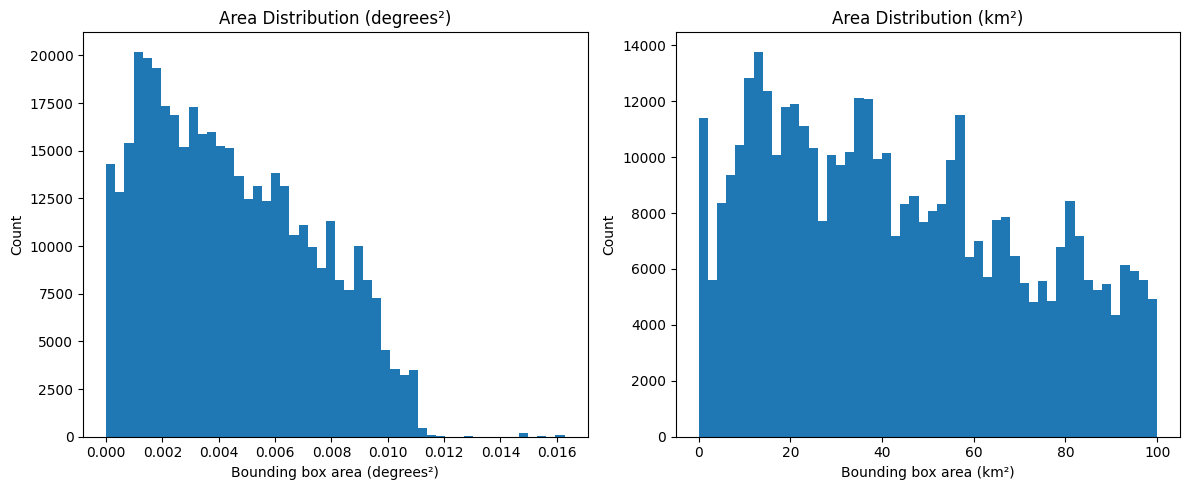

In [7]:
import gzip
import json
import numpy as np
import matplotlib.pyplot as plt

FILE = "../Extracted/1/2017-01-01.world.json.gz"

EARTH_METRES_PER_DEG = 111_320


def bbox_area_deg(points):
    lons = [p[0] for p in points]
    lats = [p[1] for p in points]
    return (max(lons) - min(lons)) * (max(lats) - min(lats))


def bbox_area_km2(points):
    lons = [p[0] for p in points]
    lats = [p[1] for p in points]

    dlon = max(lons) - min(lons)
    dlat = max(lats) - min(lats)

    lat_centre = sum(lats) / len(lats)

    width_m = dlon * EARTH_METRES_PER_DEG * np.cos(np.radians(lat_centre))
    height_m = dlat * EARTH_METRES_PER_DEG

    area_m2 = width_m * height_m
    return area_m2 / 1_000_000  # convert to km²


sizes_deg = []
sizes_km2 = []

with gzip.open(FILE, "rt", encoding="utf-8") as f:
    tweets = json.load(f)

for t in tweets:
    bbox = t.get("bounding_box")
    if bbox:
        sizes_deg.append(bbox_area_deg(bbox))
        sizes_km2.append(bbox_area_km2(bbox))

sizes_deg = np.array(sizes_deg)
sizes_km2 = np.array(sizes_km2)

# Fixed size filtering.

MAX_AREA_KM2 = 100

mask = sizes_km2 <= MAX_AREA_KM2

deg_filtered = sizes_deg[mask]
km2_filtered = sizes_km2[mask]

print("Before filtering:", len(sizes_deg))
print("After filtering :", len(deg_filtered))

print("Min Area (deg²):", deg_filtered.min())
print("Max Area (deg²):", deg_filtered.max())
print("Mean area (deg²):", deg_filtered.mean())

print("\nMin Area (km²):", km2_filtered.min())
print("Max Area (km²):", km2_filtered.max())
print("Mean area (km²):", km2_filtered.mean())


# Plots - degree² + km²
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(deg_filtered, bins=50)
plt.xlabel("Bounding box area (degrees²)")
plt.ylabel("Count")
plt.title("Area Distribution (degrees²)")

plt.subplot(1, 2, 2)
plt.hist(km2_filtered, bins=50)
plt.xlabel("Bounding box area (km²)")
plt.ylabel("Count")
plt.title("Area Distribution (km²)")

plt.tight_layout()
plt.show()

**Stats.json - Top 10 Cities**

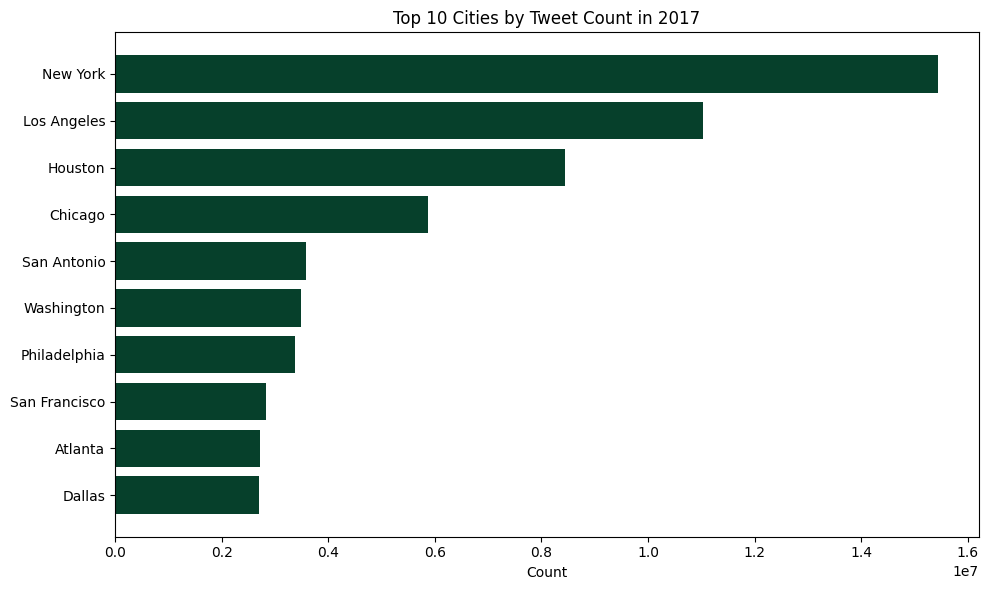

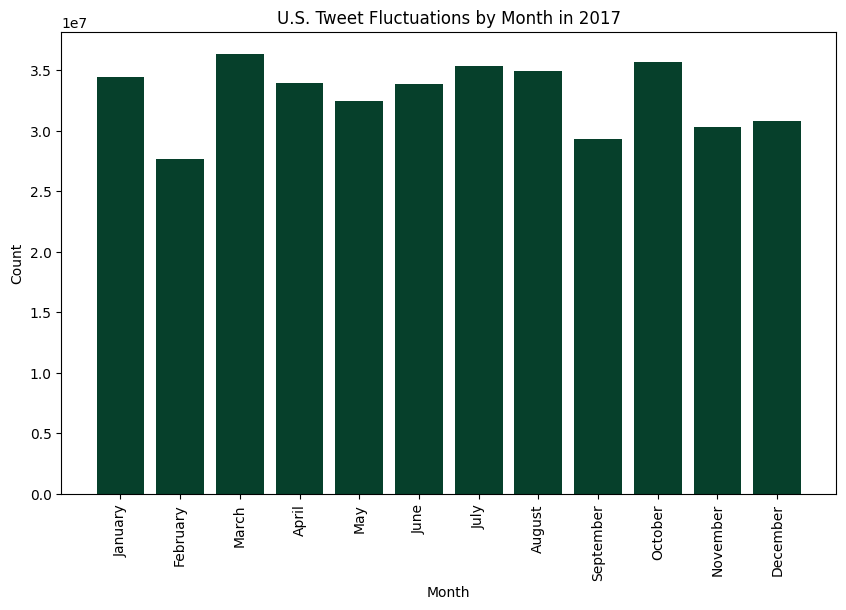

In [ ]:
import json
import matplotlib.pyplot as plt

with open("../Stats.json", "r", encoding="utf-8") as f:
    stats = json.load(f)

# ---- Whole Year Data ----

# Sort cities by count and take top 10.
top10 = sorted(
    stats['cities'].items(),
    key=lambda x : x[1],
    reverse=True
)[:10]

# Seperate counts and cities from each tuple.
cities = [c for c, _ in top10]
counts = [n for _, n in top10]

# Plot to show the top 10 cities by tweet count over the entire year.

plt.figure(figsize=(10, 6))
plt.barh(cities, counts, color='#06402B')
plt.gca().invert_yaxis()

plt.xlabel("Count")
plt.title("Top 10 Cities by Tweet Count in 2017")

plt.tight_layout()
plt.savefig("../Figures/Tweet_Count_Top10.png", dpi=300, bbox_inches="tight")
plt.show()

# ---- Month by Month Data ----

month_key = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
tweet_count = []

f = open("../General_Stats.txt", 'w')
f.write(f"Total Count: {stats['count']:,}\n\nDifferent Users: {stats['different_users']:,}\n\n")

f.write("Overall Top 10 Cities:\n\n")
for city, count in top10:
    f.write(f"{city}: {count:,}\n")


for month, data in stats["monthly"].items():

    month_name = month_key[int(month) - 1]

    tweet_count.append(data['count'])
    
    f.write(f"\n--- {month_name} ---\n\n")

    f.write(f"Total Tweets: {data['count']:,}\n\n")
    f.write(f"Total Different Users: {data['different_users']:,}\n")

    f.write(f"Top 10 Cities in {month_name}\n\n")
    

    m_top10 = sorted(
        data['cities'].items(),
        key=lambda x: x[1],
        reverse=True
    )[:10]


    for city, count in m_top10:
        f.write(f"{city}: {count:,}\n")

f.close()

plt.figure(figsize=(10,6))
plt.bar(month_key, tweet_count, color='#06402B')

plt.xlabel("Month")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.title("U.S. Tweet Fluctuations by Month in 2017")
plt.savefig("../Figures/Tweet_Count_Months.png", dpi=300, bbox_inches="tight")
plt.show()

